# **Protein architecture classification using CNNs on CATH-based contact maps.**

---
## **PAC-MAPS** (**P**rotein **A**rchitecture **C**lassification from contact **MAPS**)

A CNN that predicts a protein domain's CATH architecture (e.g. *β-barrel*, *3-layer αβα sandwich*) from its Cβ contact map alone. Every test domain comes from a **superfamily held out from training**, so the score measures generalization to new folds rather than just recognition of close homologs. The final model reaches **74% balanced accuracy across three independent superfamily splits (~10× chance over 14 classes)**, matching **Foldseek** nearest-neighbor structural search (75%) while using only a 2D contact representation.

**Key design choices**
- **Leakage-aware splits:** whole superfamilies are held out for validation and test, so no close homolog of a test domain appears in training.
- **1 pixel = 1 residue:** maps are zero-padded to 400×400, never resized, so the pixel scale of helices and strands stays physically meaningful.
- **Structure-aware input:** R = Cβ–Cβ distance (inverted, out to 30 Å), G = helix–helix pairs, B = strand–strand pairs.
- **Architecture:** a dilated residual CNN with squeeze-excitation blocks and a sequence-separation coordinate channel, trained with class-balanced sampling and a geometrically valid augmentation (N↔C sequence reversal).

**Results**

*Stage 1: architecture selection* (early pipeline: 224 px resized binary contact maps, preliminary split; numbers comparable within this table only)

| Model | Best val. bal. acc. |
|---|---|
| ResNet34 (fine-tuned) | 0.60 |
| Vanilla CNN | 0.72 |
| Dilated residual CNN + SE | 0.77 |
| **+ CoordConv (sequence separation)** | **0.82** |

*Stage 2: final pipeline* (superfamily-held-out splits, 400 px zero-padding, Cβ distance ≤ 30 Å + SSE channels, dilated CoordConv CNN, 18 epochs; one model per split)

| Split seed | Val. bal. acc. | Test acc. | Test bal. acc. |
|---|---|---|---|
| 42 | 0.696 | 0.67 | 0.69 |
| 16 | 0.701 | 0.82 | 0.77 |
| 2002 | 0.686 | 0.77 | 0.75 |
| **Mean ± SD** | **0.694 ± 0.008** | **0.75 ± 0.08** | **0.74 ± 0.04** |

*Stage 3: benchmark against Foldseek structural search* (same three test sets; Foldseek searches each seed's test domains against that seed's training domains only)

| Method | Input | Test acc. | Test bal. acc. |
|---|---|---|---|
| **PAC-MAPS** | 2D Cβ distance map + SSE channels | 0.75 ± 0.08 | **0.74 ± 0.04** |
| Foldseek, top-1 nearest neighbor | full 3D structure | 0.80 ± 0.04 | 0.73 ± 0.05 |
| Foldseek, top-5 majority vote | full 3D structure | **0.81 ± 0.04** | **0.75 ± 0.05** |


PAC-MAPS matches Foldseek nearest-neighbor structural search on balanced accuracy (74 ± 4% vs. 75 ± 5%, top-5) while using only a 2D contact representation, though Foldseek achieves higher overall accuracy (81% vs. 75%), driven by better performance on the largest architectures. The two methods distribute their errors differently: PAC-MAPS's accuracy and balanced accuracy are nearly equal, while Foldseek is stronger on the large classes that dominate plain accuracy.

*Each seed holds out a different set of superfamilies for validation and test; every method is evaluated only on its own split's test set. SD is the sample standard deviation across seeds. Foldseek was run with `easy-search` in exhaustive mode (E ≤ 10); top-5 ties are broken by summed bit score, and the ~2% of queries with no hit are counted as errors. Chance balanced accuracy ≈ 7% (14 classes). Small classes such as 3.50 may be absent from some test sets, so per-seed balanced accuracy can cover slightly different class sets. Full training logs: [W&B project](https://wandb.ai/murto-university-of-waterloo/protein-architecture-classification).*

## **0. Dependencies & imports**

In [ ]:
! pip install fastai
! pip install pandas
! pip install numpy
! pip install scikit-learn
! pip install Pillow
! pip install biotite
! pip install sympy==1.13.3
! pip install --upgrade wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 73.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 51.5 MB/s eta 0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 6.9 MB/s eta 0:00:00
  Attempting uninstall: opentelemetry-api
    Found existing installation: opentelemetry-api 1.42.1
    Uninstalling opentelemetry-api-1.42.1:
      Successfully uninstalled opentelemetry-api-1.42.1
  Attempting uninstall

In [63]:
# general tools
import os
import gc
import shutil
import warnings
warnings.filterwarnings("ignore", module="sklearn")
import pandas as pd
import numpy as np
import biotite.structure.io.pdb as pdb
import biotite.structure as struc
from tqdm.auto import tqdm
from PIL import Image
from multiprocessing import Pool
import matplotlib.pyplot as plt
import seaborn as sns

# ML/DL tools
import wandb
import timm
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from fastai.vision.all import FuncSplitter
from fastai.vision.all import *
from fastai.callback.wandb import *
from fastai.distributed import *

1. Set WANDB_ENTITY (and optionally WANDB_PROJECT) to your own account values.
2. Get a free API key from [W&B](https://forge.coreweave.com/wandb/authorize?ref=models).
3. Add it as a secret named WANDB_API_KEY from the left in the key icon and give this notebook access.

In [ ]:
# ============================================================
# Config: edit these for your own W&B account
# ============================================================
WANDB_PROJECT = "protein-architecture-classification"
WANDB_ENTITY  = "murto-university-of-waterloo"   # <- change me

os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["WANDB_ENTITY"]  = WANDB_ENTITY
os.environ["WANDB_NOTEBOOK_NAME"] = "PAC-MAPS.ipynb"

# W&B API Key
def get_wandb_key():
    try:                                    # Google Colab: 🔑 sidebar → add secret WANDB_API_KEY
        from google.colab import userdata
        return userdata.get("WANDB_API_KEY")
    except ImportError:
        pass
    from getpass import getpass
    return getpass("W&B API key: ")

import wandb
wandb.login(key=get_wandb_key())

wandb: WARNING WANDB_NOTEBOOK_NAME should be a path to a notebook file, couldn't find PAC-MAPS.ipynb.
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: murto (murto-university-of-waterloo) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## **1. Data preparation**



### **1.1. First, we import CATH's non redundant protein domain data**

In [ ]:
! apt-get install -y aria2
! aria2c -s 4 -x 4 ftp://orengoftp.biochem.ucl.ac.uk/cath/releases/latest-release/non-redundant-data-sets/cath-dataset-nonredundant-S40.pdb.tgz
! aria2c -s 4 -x 4 ftp://orengoftp.biochem.ucl.ac.uk/cath/releases/latest-release/non-redundant-data-sets/cath-dataset-nonredundant-S40.list
! aria2c -s 4 -x 4 ftp://orengoftp.biochem.ucl.ac.uk/cath/releases/latest-release/cath-classification-data/cath-domain-list.txt
! aria2c -s 4 -x 4 ftp://orengoftp.biochem.ucl.ac.uk/cath/releases/latest-release/cath-classification-data/cath-names.txt -d /content/ -o cath-names.txt
! tar -xzf cath-dataset-nonredundant-S40.pdb.tgz


Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libaria2-0 libcares2
The following NEW packages will be installed:
  aria2 libaria2-0 libcares2
0 upgraded, 3 newly installed, 0 to remove and 0 not upgraded.
Need to get 1,566 kB of archives.
After this operation, 5,692 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libcares2 amd64 1.27.0-1.0ubuntu1 [73.7 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libaria2-0 amd64 1.37.0+debian-1build3 [1,105 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/universe amd64 aria2 amd64 1.37.0+debian-1build3 [387 kB]
Fetched 1,566 kB in 1s (1,603 kB/s)
Selecting previously unselected package libcares2:amd64.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../libcares2_1.27.0-1.0ubuntu1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1) ...
Selecting previousl

### **1.2. Next, we'll label all of the data from our non-redundant set using `cath-domain-list.txt`**

In [ ]:
cath_domain_list = pd.read_csv('cath-domain-list.txt', sep='\s+', header=None, names=['id', 'c', 'a', 't', 'h', 's35', 's60', 's95', 's100', 's100_count', 'domain_length', 'resolution'], comment='#')
# data on column definition was found at https://github.com/wukevin/proteinclip/blob/main/data/cath/README-cath-list-file-format.txt
cath_domain_list.head()

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3856/1016858256.py:1: SyntaxWarning: invalid escape sequence '\s'
  cath_domain_list = pd.read_csv('cath-domain-list.txt', sep='\s+', header=None, names=['id', 'c', 'a', 't', 'h', 's35', 's60', 's95', 's100', 's100_count', 'domain_length', 'resolution'], comment='#')


,id,c,a,t,h,s35,s60,s95,s100,s100_count,domain_length,resolution
0,1oaiA00,1,10,8,10,1,1,1,1,1,59,1.0
1,1go5A00,1,10,8,10,1,1,1,1,2,69,999.0
2,3frhA01,1,10,8,10,2,1,1,1,1,58,1.2
3,3friA01,1,10,8,10,2,1,1,1,2,54,1.8
4,3b89A01,1,10,8,10,2,1,1,2,1,54,2.6


In [ ]:
with open('cath-dataset-nonredundant-S40.list') as f:
  cath_list = f.readlines()

cath_list = [x.strip() for x in cath_list]

cath_list[:10]

['12asA00',
 '152lA00',
 '153lA00',
 '155cA00',
 '16pkA02',
 '16vpA00',
 '17gsA01',
 '1914A00',
 '19hcA01',
 '19hcA02']

In [ ]:
s40 = pd.DataFrame({"id": cath_list}).merge(
    cath_domain_list[["id", "c", "a", "t", "h", "domain_length"]], on="id", how="left")

s40["architecture"] = s40.c.astype(str) + "." + s40.a.astype(str)         # e.g. 3.40
s40["topology"]     = s40.architecture + "." + s40.t.astype(str)          # e.g. 3.40.50
s40["superfamily"]  = s40.topology + "." + s40.h.astype(str)              # e.g. 3.40.50.300

print(s40.c.isna().sum(), "S40 ids missing from the domain list")  # should be 0

0 S40 ids missing from the domain list


### **1.3. Let's do some basic EDA & filtering**



<Axes: xlabel='architecture'>

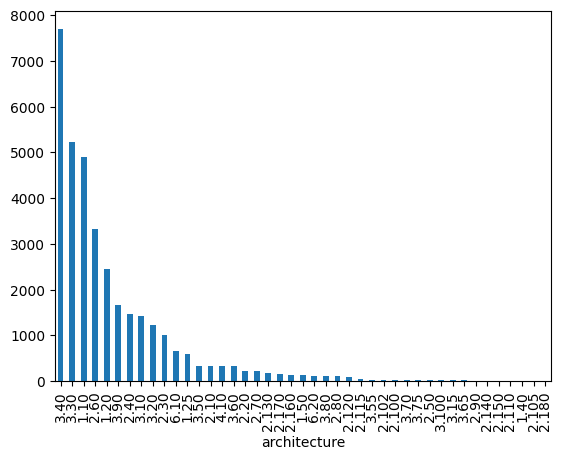

In [ ]:
s40['architecture'].value_counts().plot(kind='bar')

,domain_length
count,34653.000000
mean,154.111679
std,88.736003
min,9.000000
25%,93.000000
50%,132.000000
75%,194.000000
max,1202.000000


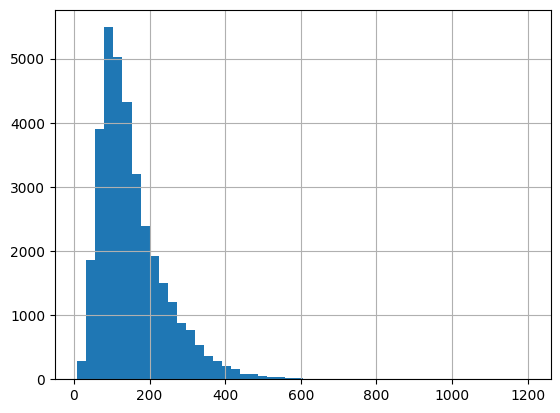

In [ ]:
s40['domain_length'].hist(bins=50)
s40['domain_length'].describe()

In [ ]:
# let's check what portion of the dataset remains after trimming at 1200, 1100, 1000 etc.
total = len(s40)
for n in range(1200, 0, -100):
  remaining = s40[s40['domain_length'] < n]
  print(f"Cutoff @ {n}:\t {len(remaining) / total * 100:1f}%")

Cutoff @ 1200:	 99.997114%
Cutoff @ 1100:	 99.994228%
Cutoff @ 1000:	 99.988457%
Cutoff @ 900:	 99.979800%
Cutoff @ 800:	 99.959599%
Cutoff @ 700:	 99.927856%
Cutoff @ 600:	 99.867255%
Cutoff @ 500:	 99.535394%
Cutoff @ 400:	 98.193519%
Cutoff @ 300:	 92.710588%
Cutoff @ 200:	 76.397426%
Cutoff @ 100:	 29.890630%


In [ ]:
# subset to domain length under 400 for easier downstream computation (retains 98% of data)
s40 = s40[s40['domain_length'] < 400]

In [ ]:
# drop from architectures with less than 100 samples
topology_counts = s40.topology.value_counts()
valid_topologies = topology_counts[topology_counts > 100].index
s40 = s40[s40.topology.isin(valid_topologies)]

<Axes: xlabel='architecture'>

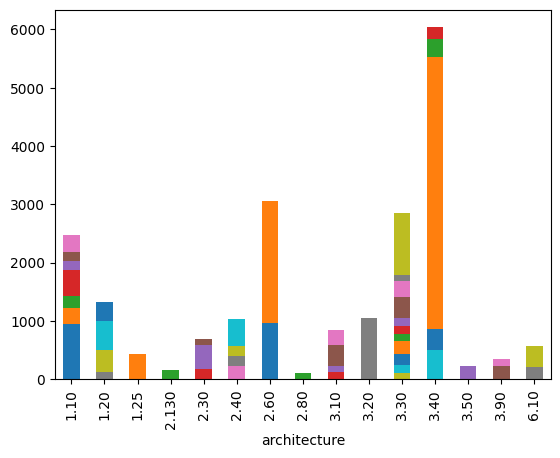

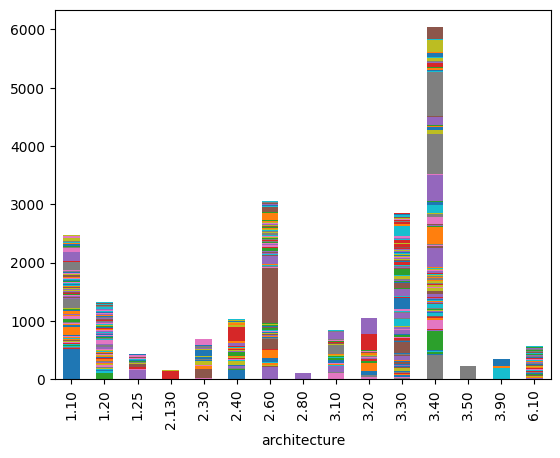

In [ ]:
# graph how many topology and superfamily types there are per architecture
s40.groupby('architecture')['topology'].value_counts().unstack().plot(kind='bar', stacked=True, legend=False)
s40.groupby('architecture')['superfamily'].value_counts().unstack().plot(kind='bar', stacked=True, legend=False)

We want to turn each of these PDBs into images. One way to represent proteins graphically is with contact maps, where pixel values represent the distance (in angstroms) between each residue and every other residue in a heatmap-like format. Specifically, I use the distance between Cβ atoms to best capture side-chain geometry in the contacts.

Since pixels have 3 channels (R, G, B) we can encode different kinds of information in each.

- R: Continue carbon beta distances inverted and normalized between 0 and 30 A.
- G: 0 / 255 depending on if both residues are helices.
- B: 0 / 255 depending on if both residues are strands.

In [ ]:
D_MAX = 30.0
def map_to_png(pdb_path, out_path):
    """
    R: continuous Cβ–Cβ distance, inverted and clipped (255 = touching, 0 = >= D_MAX Å)
    G: 255 where residue i AND residue j are both helix
    B: 255 where residue i AND residue j are both strand
    One pixel per residue, same as before.
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        s = pdb.PDBFile.read(pdb_path).get_structure(model=1)

    prot = s[~s.hetero]  # same filtering as before so residue counts don't change

    # one SSE label per residue, in the same order as residue_iter: 'a' helix, 'b' strand, 'c' coil
    sse = struc.annotate_sse(prot)

    coords, ss = [], []
    for res, label in zip(struc.residue_iter(prot), sse):
        sel = res[res.atom_name == "CB"]
        if len(sel) == 0:
            sel = res[res.atom_name == "CA"]  # glycine, or a Cα-only residue
        if len(sel):
            coords.append(sel.coord[0])
            ss.append(label)

    if len(coords) < 2:
        raise ValueError(f"only {len(coords)} usable residues in {pdb_path}")

    cb = np.array(coords)
    ss = np.array(ss)
    d = np.linalg.norm(cb[:, None] - cb[None], axis=-1)

    r = np.clip(1.0 - d / D_MAX, 0.0, 1.0)

    helix = ss == "a"
    strand = ss == "b"
    g = helix[:, None] & helix[None, :]
    b = strand[:, None] & strand[None, :]

    img = (np.stack([r, g, b], axis=-1) * 255).astype(np.uint8)
    Image.fromarray(img).save(out_path, format="PNG")

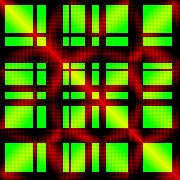

In [ ]:
map_to_png('/content/dompdb/1a22A00', 'test.png')

from IPython.display import Image as ipImage
ipImage(filename='test.png')

### **1.4. We'll create folders for each image based on the architecture label**


Dataset is available for download here and on Kaggle. Takes ~11 min to generate.

In [ ]:
# assign each CATH architecture its human-readable name
cath_names = {}

with open("/content/cath-names.txt", "r") as f:
    for line in f:
        # Skip comments or empty lines
        if line.startswith("#") or not line.strip():
            continue

        # Split into [CATH_ID, Level, Name]
        parts = line.strip().split(maxsplit=2)
        if len(parts) == 3:
            cath_id, level, name = parts

            # sanitize the name to use as a folder path
            safe_name = re.sub(r'[^a-zA-Z0-9_]', '_', name)
            cath_names[cath_id] = f"{cath_id}_{safe_name}"

In [ ]:
# generate contact map images
OUT_ROOT = "/content/s40"

def _job(row):
    rid, arch = row
    folder_name = cath_names.get(arch, arch)
    out_dir = f"{OUT_ROOT}/{folder_name}"
    os.makedirs(out_dir, exist_ok=True)
    try:
        map_to_png(f"/content/dompdb/{rid}", f"{out_dir}/{rid}.png")
        return None
    except Exception as e:
        return (rid, str(e))

rows = list(zip(s40.id, s40.architecture.astype(str)))
with Pool(os.cpu_count()) as pool:
    failures = [f for f in tqdm(pool.imap_unordered(_job, rows, chunksize=64), total=len(rows)) if f]

print(f"{len(failures)} failures")
failures[:10]

  0%|          | 0/21079 [00:00<?, ?it/s]

0 failures


[]

In [ ]:
! tar -czvf s40_updated.tar.gz /content/s40

Streaming output truncated to the last 5000 lines.
/content/s40/3.30__2_Layer_Sandwich/2pt7G01.png
/content/s40/3.30__2_Layer_Sandwich/3hvwA00.png
/content/s40/3.30__2_Layer_Sandwich/2jwnA01.png
/content/s40/3.30__2_Layer_Sandwich/3byqA00.png
/content/s40/3.30__2_Layer_Sandwich/5nqdA01.png
/content/s40/3.30__2_Layer_Sandwich/1nt2A01.png
/content/s40/3.30__2_Layer_Sandwich/3i9v900.png
/content/s40/3.30__2_Layer_Sandwich/2ku3A00.png
/content/s40/3.30__2_Layer_Sandwich/8f4rA02.png
/content/s40/3.30__2_Layer_Sandwich/5dk5A01.png
/content/s40/3.30__2_Layer_Sandwich/3zeuB02.png
/content/s40/3.30__2_Layer_Sandwich/2etjA00.png
/content/s40/3.30__2_Layer_Sandwich/2qv6A01.png
/content/s40/3.30__2_Layer_Sandwich/2hp0A02.png
/content/s40/3.30__2_Layer_Sandwich/1ny8A00.png
/content/s40/3.30__2_Layer_Sandwich/3ms6A00.png
/content/s40/3.30__2_Layer_Sandwich/1zc6A02.png
/content/s40/3.30__2_Layer_Sandwich/5dx9A01.png
/content/s40/3.30__2_Layer_Sandwich/1noyB02.png
/content/s40/3.30__2_Layer_Sandwich/3

## **2. Data set up & augmentation**

Here, I'm going to set up the DataLoaders & build an augmentation strategy.

### **2.1. First, let's define a splitter.**

To ensure the model actually learns how to map contact map geometry to architecture, we'll want to make sure our test set doesn't look anything like our training set.

If we don't, strong results could simply mean the model has *'memorized'* the answer.

To remedy this, we'll **hold out specific superfamilies** (the two levels below architecture) from each architecture group; that way, we'll know how the model performs on previously unseen evolutionary groups. This benchmarking approach is similar to the one employed for the [DockGen](https://arxiv.org/abs/2402.18396) benchmark as well as [Chainsaw](https://academic.oup.com/bioinformatics/article/40/5/btae296/7667299). For extra robustness, our validation set will *also* comprise of unseen superfamilies.

In [ ]:
! tar -xzf s40_updated.tar.gz


gzip: stdin: unexpected end of file
tar: Unexpected EOF in archive
tar: Unexpected EOF in archive
tar: Error is not recoverable: exiting now


In [ ]:
TEST_FRAC  = 0.10   # target share of each architecture's domains in test
VALID_FRAC = 0.10   # target share in validation
MAX_SHARE  = 0.15   # superfamilies bigger than this share of their class stay in train
TOL        = 0.5    # allow a split to overshoot its target by up to 50% (e.g. 10% -> 15%)
SEED       = 2002     # random seed (16, 42, 2002)

rng = np.random.default_rng(SEED)

def split_architecture(counts):
    """Greedily assign whole superfamilies to test/valid until each hits its target.
    Returns (test_sfs, valid_sfs); everything else stays in train."""
    total = counts.sum()
    shares = counts / total

    # only small/medium superfamilies are eligible for holding out
    eligible = shares[shares <= MAX_SHARE].index.to_numpy()
    rng.shuffle(eligible)

    test, valid = [], []
    t_n = v_n = 0
    t_target, v_target = TEST_FRAC * total, VALID_FRAC * total

    for sf in eligible:
        n = counts[sf]
        if t_n < t_target and (t_n + n <= (1 + TOL) * t_target or not test):
            test.append(sf); t_n += n
        elif v_n < v_target and (v_n + n <= (1 + TOL) * v_target or not valid):
            valid.append(sf); v_n += n
        if t_n >= t_target and v_n >= v_target:
            break

    # fallback: every superfamily was too big -> use the smallest ones not yet used,
    # always leaving at least one superfamily (the largest) in train
    leftovers = [sf for sf in counts.sort_values().index[:-1] if sf not in test and sf not in valid]
    if not test and leftovers:
        test.append(leftovers.pop(0))
    if not valid and leftovers:
        valid.append(leftovers.pop(0))

    return test, valid

test_superfamilies, valid_superfamilies, skipped, report = set(), set(), [], []

for arch, g in s40.groupby("architecture"):
    counts = g.superfamily.value_counts()
    if len(counts) < 3:
        skipped.append(arch); continue  # can't hold out test & val and still train

    test, valid = split_architecture(counts)
    test_superfamilies |= set(test)
    valid_superfamilies |= set(valid)

    total = counts.sum()
    report.append({
        "arch": arch,
        "n": total,
        "n_sf": len(counts),
        "test_frac": counts[test].sum() / total,
        "valid_frac": counts[valid].sum() / total,
        "test_sf": len(test),
        "valid_sf": len(valid),
        # how dominated is val by a single superfamily? (high = noisy val metric)
        "valid_top_sf_share": counts[valid].max() / counts[valid].sum() if valid else np.nan,
    })

assert not (test_superfamilies & valid_superfamilies)

# assign train / val / test split into DataFrames
test_ids  = set(s40.id[s40.superfamily.isin(test_superfamilies)])
valid_ids = set(s40.id[s40.superfamily.isin(valid_superfamilies)])

dev_df  = s40[~s40.id.isin(test_ids) & ~s40.architecture.isin(skipped)].copy()  # train + val
test_df = s40[s40.id.isin(test_ids)].copy()

splitter = FuncSplitter(lambda p: p.stem in valid_ids)

print(f"Train/Val pool: {len(dev_df)} domains ({len(valid_ids)} in Val, "
      f"{len(valid_superfamilies)} superfamilies)")
print(f"Vaulted Test: {len(test_df)} domains across {len(test_superfamilies)} superfamilies")
print(f"Skipped architectures (< 3 superfamilies): {skipped}")

split_report = pd.DataFrame(report).set_index("arch").round(3)
split_report

Train/Val pool: 18714 domains (2519 in Val, 380 superfamilies)
Vaulted Test: 2365 domains across 472 superfamilies
Skipped architectures (< 3 superfamilies): []


,n,n_sf,test_frac,valid_frac,test_sf,valid_sf,valid_top_sf_share
arch,,,,,,,
1.10,2471,552,0.142,0.143,89,58,0.424
1.20,1321,472,0.104,0.101,28,46,0.231
1.25,430,89,0.107,0.100,14,21,0.209
2.130,152,7,0.105,0.013,4,2,0.500
2.30,696,110,0.102,0.105,20,12,0.589
2.40,1035,194,0.102,0.102,39,31,0.358
2.60,3065,450,0.107,0.101,85,95,0.120
3.10,845,130,0.115,0.101,16,39,0.212
3.20,1042,29,0.112,0.144,11,6,0.813


In [ ]:
# subset to held samples, get rid of unneeded ones
s40 = s40[~s40.architecture.isin(skipped)]

skip_dir = Path("/content/skipped")
skip_dir.mkdir(exist_ok=True)

for arch in skipped:
    arch_path = Path("/content/s40") / cath_names.get(arch, arch)
    if arch_path.exists():
        for f in arch_path.iterdir():
            f.rename(skip_dir / f.name)
        arch_path.rmdir()
    else:
        print(f"WARNING: no folder found for skipped architecture {arch} at {arch_path}")

### **2.2. Now, let's create the DataBlocks to load into `fastai`.**

Since the labels are unbalanced, we'll weight them differently to allow oversampling from the underrepresented groups.

From our valid superfamilies training set, we'll calculate the weights for each architecture:

> **Typical computer vision data augmentation strategies don't necessarily apply to these protein contact maps**. A bird rotated 180 degrees is still a bird — a protein contact map loses its meaning. Transforms, flips, and rotations work well for natural images, but contact maps follow strict geometry with diagonal symmetry. As such, we'll experiment with a custom transform, the anti-diagonal flip which flips both spatial dimensions at once to simulate N-C sequence inversion.

In [ ]:
class AntiDiagonalFlip(RandTransform):
    """
    Simulates N-to-C terminal sequence inversion.
    Flips across both spatial dimensions (H, W) simultaneously,
    keeping the main diagonal intact and preserving pairwise distance symmetry.
    """
    order = 10  # Run after standard tensor conversions
    def __init__(self, p=0.5):
        super().__init__(p=p)

    def encodes(self, x: TensorImage):
        # Tensor shape: [batch_size, channels, H, W]
        return torch.flip(x, dims=[-2, -1])

In [ ]:
# preparing images for DataLoaders
# especially pulling weights since we have imblanced classes
path = Path("/content/s40")
items = get_image_files(path)

# isolate the train IDs (excluding both val and test superfamilies)
train_ids = set(s40.id[~s40.superfamily.isin(valid_superfamilies | test_superfamilies)])

# 2. filter items to only include the dev pool (Train + Valid) for DataBlock
dev_items = [p for p in items if p.stem not in test_ids]

# 3. compute class counts strictly on the training set
train_labels = [parent_label(p) for p in dev_items if p.stem in train_ids]
train_counts = Counter(train_labels)

# 4. build sample weights matching len(dev_items); 0.0 for validation items
wgts = np.array([
    (1.0 / train_counts[parent_label(p)]) if p.stem in train_ids else 0.0
    for p in dev_items
])

In [ ]:
# 3.1 Build DataBlock with uniform sizing and no augmentation
contact_map_block = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    splitter=splitter,
    get_y=parent_label,
    item_tfms=CropPad(400)
)

dls = contact_map_block.weighted_dataloaders(dev_items, wgts=wgts, bs=16)

In [ ]:
# 3.2 Build DataBlock with uniform sizing and augmentation
contact_map_block_aug = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    splitter=splitter,
    get_y=parent_label,
    item_tfms=CropPad(400), # standardizes spatial size on CPU
    batch_tfms=[
        IntToFloatTensor(),
        AntiDiagonalFlip(p=0.5), # physically valid sequence reversal
        Normalize.from_stats(*imagenet_stats)
    ]
)

dls_aug = contact_map_block_aug.weighted_dataloaders(dev_items, wgts=wgts, bs=32)

In [ ]:
# 3.3 Unweighted DataLoader for Focal Loss training with augmentations
contact_map_block_aug_uw = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    splitter=splitter,
    get_y=parent_label,
    item_tfms=CropPad(400),
    batch_tfms=[
        IntToFloatTensor(),
        AntiDiagonalFlip(p=0.5),
        Normalize.from_stats(*imagenet_stats)
    ]
)

dls_aug_uw = contact_map_block_aug_uw.dataloaders(dev_items, bs=16)

## **3. Model training**

 Next, we train the model to recognize protein families from a contact map / protein structure. We'll experiment with:

 1. Fine-tuning ResNet.
 2. Training a vanilla CNN from scratch.
 3. Training a residual CNN from scratch.
 4. Training a residual CNN with CoordConv layers.

### **3.1. Fine-tuning on ResNet**

In [ ]:
wandb.init(config=dict(model="ResNet34", aug=False))

learn = vision_learner(
    dls,
    xresnet34,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.3,
    cbs=[
        WandbCallback()
    ],
    ps=0.5
)

learn.freeze()

with learn.parallel_ctx():
    learn.fit_one_cycle(5, lr_max=1e-3)

learn.unfreeze()

with learn.parallel_ctx():
    learn.fit_one_cycle(10, lr_max=slice(1e-6, 1e-4))

wandb.finish()

In [ ]:
wandb.init(config=dict(model="ResNet34", aug=True))

learn = vision_learner(
    dls_aug,
    xresnet34,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.3,
    cbs=[
        WandbCallback()
    ],
    ps=0.5
)

learn.freeze()

with learn.parallel_ctx():
    learn.fit_one_cycle(5, lr_max=1e-3)

learn.unfreeze()

with learn.parallel_ctx():
    learn.fit_one_cycle(10, lr_max=slice(1e-6, 1e-4))

wandb.finish()

### **3.2. Vanilla CNN**

In [ ]:
class ContactMapCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [ ]:
wandb.init(config=dict(model="ContactMapCNN", aug=False))

model = ContactMapCNN(num_classes=dls.c)

learn = Learner(
    dls,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.05,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_contact_cnn')
    ]
)

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=5e-4)

wandb.finish()

In [ ]:
wandb.init(config=dict(model="ContactMapCNN", aug=True))

model = ContactMapCNN(num_classes=dls_aug.c)

learn = Learner(
    dls_aug,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.05,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_contact_cnn')
    ]
)

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=5e-4)

wandb.finish()

### **3.3. Residual CNN**

In [ ]:
class SqueezeExcitation(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)

        # The excitation network acts as a channel-wise gate
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        # Squeeze spatial dimensions to 1x1
        y = self.squeeze(x).view(b, c)
        # Calculate channel weights
        y = self.excitation(y).view(b, c, 1, 1)
        # Scale the original input feature maps
        return x * y.expand_as(x)

In [ ]:
class DilatedResidualBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, channels, kernel_size=3, padding=dilation, dilation=dilation, bias=False
        )
        self.bn1 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            channels, channels, kernel_size=3, padding=1, dilation=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(channels)
        self.se = SqueezeExcitation(channels)

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = self.se(out)

        out += residual

        return self.relu(out)

class DilatedContactMapCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.dilated_blocks = nn.Sequential(
            DilatedResidualBlock(64, dilation=1),
            DilatedResidualBlock(64, dilation=2),
            DilatedResidualBlock(64, dilation=4),
            DilatedResidualBlock(64, dilation=8)
        )

        self.downsample = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False), # 224 -> 112
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1, bias=False), # 112 -> 56
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.dilated_blocks(x)
        x = self.downsample(x)
        return self.classifier(x)

In [ ]:
wandb.init(config=dict(model="DilatedContactMapCNN", aug=False))

model = DilatedContactMapCNN(num_classes=dls.c)

learn = Learner(
    dls,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.01,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(max_norm=1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_dilated_cnn')
    ]
).to_fp16()

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=3e-4)

wandb.finish()

In [ ]:
wandb.init(config=dict(model="DilatedContactMapCNN", aug=True))

model = DilatedContactMapCNN(num_classes=dls_aug.c)

learn = Learner(
    dls_aug,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.01,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(max_norm=1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_dilated_cnn')
    ]
).to_fp16()

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=3e-4)

wandb.finish()

### **3.4. Residual CoordConv**

In [ ]:
class ContactCoordConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False):
        super().__init__()

        self.conv = nn.Conv2d(in_channels + 1, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)

    def forward(self, x):
        bs, _, h, w = x.shape
        i = torch.arange(h, device=x.device, dtype=x.dtype).view(1, 1, h, 1)
        j = torch.arange(w, device=x.device, dtype=x.dtype).view(1, 1, 1, w)
        seq_sep = (torch.log1p((i - j).abs()) / math.log1p(max(h, w))).expand(bs, 1, h, w)
        return self.conv(torch.cat([x, seq_sep], dim=1))

class DilatedCoordContactCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.stem = nn.Sequential(
            ContactCoordConv2d(3, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        # Dilated residual stack (receptive field expansion)
        self.dilated_blocks = nn.Sequential(
            DilatedResidualBlock(64, dilation=1),
            DilatedResidualBlock(64, dilation=2),
            DilatedResidualBlock(64, dilation=4),
            DilatedResidualBlock(64, dilation=8),
            DilatedResidualBlock(64, dilation=16)
        )

        # Downsampling block
        self.downsample = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            AdaptiveConcatPool2d()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.dilated_blocks(x)
        x = self.downsample(x)
        return self.classifier(x)

Dilated CoordConv CNN on basic DataLoader

In [ ]:
wandb.init(config=dict(model="DilatedCoordContactCNN", aug=False, canvas=400, d_max=30, lr_max=2e-4, epochs=18, split_seed=SEED))

model = DilatedCoordContactCNN(num_classes=dls.c)

learn = Learner(
    dls,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.01,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(max_norm=1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_dilated_coord_cnn')
    ]
).to_fp16()

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=3e-4)

wandb.finish()

Dilated CoordConv CNN on augmented DataLoader

In [ ]:
wandb.init(config=dict(model="DilatedCoordContactCNN", aug=True, canvas=400, d_max=30, lr_max=2e-4, epochs=18, split_seed=SEED))

learn = Learner(
    dls_aug,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.01,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(max_norm=1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_dilated_coord_cnn')
    ]
).to_fp16()

with learn.parallel_ctx():
  learn.fit_one_cycle(18, lr_max=2e-4)

wandb.finish()

epoch,train_loss,valid_loss,accuracy,balanced_accuracy_score,time
0,1.861449,1.829200,0.298928,0.436788,04:32
1,1.119052,1.310127,0.520842,0.544005,04:32
2,0.763691,1.304317,0.543470,0.554386,04:32
3,0.557330,1.291366,0.616117,0.575358,04:32
4,0.450324,1.158364,0.702263,0.571622,04:33
5,0.402985,1.259144,0.694323,0.622808,04:33
6,0.341921,1.213861,0.772926,0.692387,04:33
7,0.282963,1.311864,0.764589,0.694125,04:34
8,0.286233,1.204173,0.772926,0.680287,04:34
9,0.232458,1.388284,0.741961,0.666503,04:34


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Better model found at epoch 0 with balanced_accuracy_score value: 0.43678842867100787.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Better model found at epoch 1 with balanced_accuracy_score value: 0.5440048672338789.


...

Better model found at epoch 14 with balanced_accuracy_score value: 0.6942576603494158.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Better model found at epoch 15 with balanced_accuracy_score value: 0.6973308422560051.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


accuracy,▁▄▄▆▇▇███▇████████
balanced_accuracy_score,▁▄▄▅▅▆███▇▇███████
epoch,▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇█
eps_0,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr_0,▁▂▂▃▄▆▆▆▇██████████▇▇▇▇▇▆▆▆▆▄▄▃▃▃▃▃▂▁▁▁▁
mom_0,███▇▆▄▃▂▂▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▃▄▄▅▅▅▅▆▇▇▇█████
raw_loss,█▇▅▅▅▄▃▃▂▂▃▂▂▂▂▂▂▂▂▂▁▁▁▂▂▁▁▁▁▂▁▂▂▁▁▂▂▁▁▂
sqr_mom_0,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▅▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_samples_per_sec,█▆▄▄▅▄▆▆▇▅▄▇▆▆▆▇▇▁▃▄▆▄▆▆█▅▇▇▇█▄▇▆▆▆▆▆▆▇▇
+2,...


Unweighted DataLoader trained with FocalLoss function

In [ ]:
wandb.init(config=dict(model="DilatedCoordContactCNN", aug=True, canvas=400, d_max=30, lr_max=2e-4, epochs=18, split_seed=SEED))

model = DilatedCoordContactCNN(num_classes=dls_aug_uw.c)

# build alpha weights for the FocalLoss function
total_samples = sum(train_counts.values())
n_classes = len(dls_aug_uw.vocab)

# formula = total / (n_classes * count)
alpha_weights = [total_samples / (n_classes * train_counts.get(c, 1)) for c in dls_aug_uw.vocab]

# push to GPU and clamp the maximum multiplier to prevent fp16 gradient explosions
alpha_tensor = torch.tensor(alpha_weights, dtype=torch.float32).cuda()
alpha_tensor = torch.clamp(alpha_tensor, max=10.0)

learn = Learner(
    dls_aug_uw,
    model,
    loss_func=FocalLossFlat(gamma=2.0, weight=alpha_tensor),
    metrics=[accuracy, BalancedAccuracy()],
    wd=0.01,
    cbs=[
        WandbCallback(log_preds=False),
        GradientClip(max_norm=1.0),
        SaveModelCallback(monitor='balanced_accuracy_score', fname='best_dilated_coord_cnn_uw')
    ]
).to_fp16()

with learn.parallel_ctx():
    learn.fit_one_cycle(15, lr_max=3e-4)

wandb.finish()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: ERROR Invalid API key: API key may only contain the letters A-Z, digits and underscores.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

...

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: murto (murto-university-of-waterloo) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


NameError: name 'dls_aug_uw' is not defined

## **4. Model testing**
Now, it's time to measure the model's performance on a test set comprised of entirely unseen protein superfamilies.

### **4.1. Test set accuracy and balanced accuracy**

In [ ]:
test_files = [p for p in items if p.stem in test_ids]
test_dl = dls_aug.test_dl(test_files, with_labels=True)

print("Test DataLoader built.")

test_dl.to('cuda')
learn.model.to('cuda')
learn.to_fp16()

print("Model set to cuda")

learn.remove_cb(WandbCallback)

print("Beginning test...")
preds, targets = learn.get_preds(dl=test_dl)

pred_labels = preds.argmax(dim=-1).numpy()
true_labels = targets.numpy()

print("\033[1mFinal Test Accuracy:\033[0m", accuracy_score(true_labels, pred_labels))
print("\033[1mFinal Test Balanced Accuracy:\033[0m", balanced_accuracy_score(true_labels, pred_labels))

### **4.2. Confusion matrix**



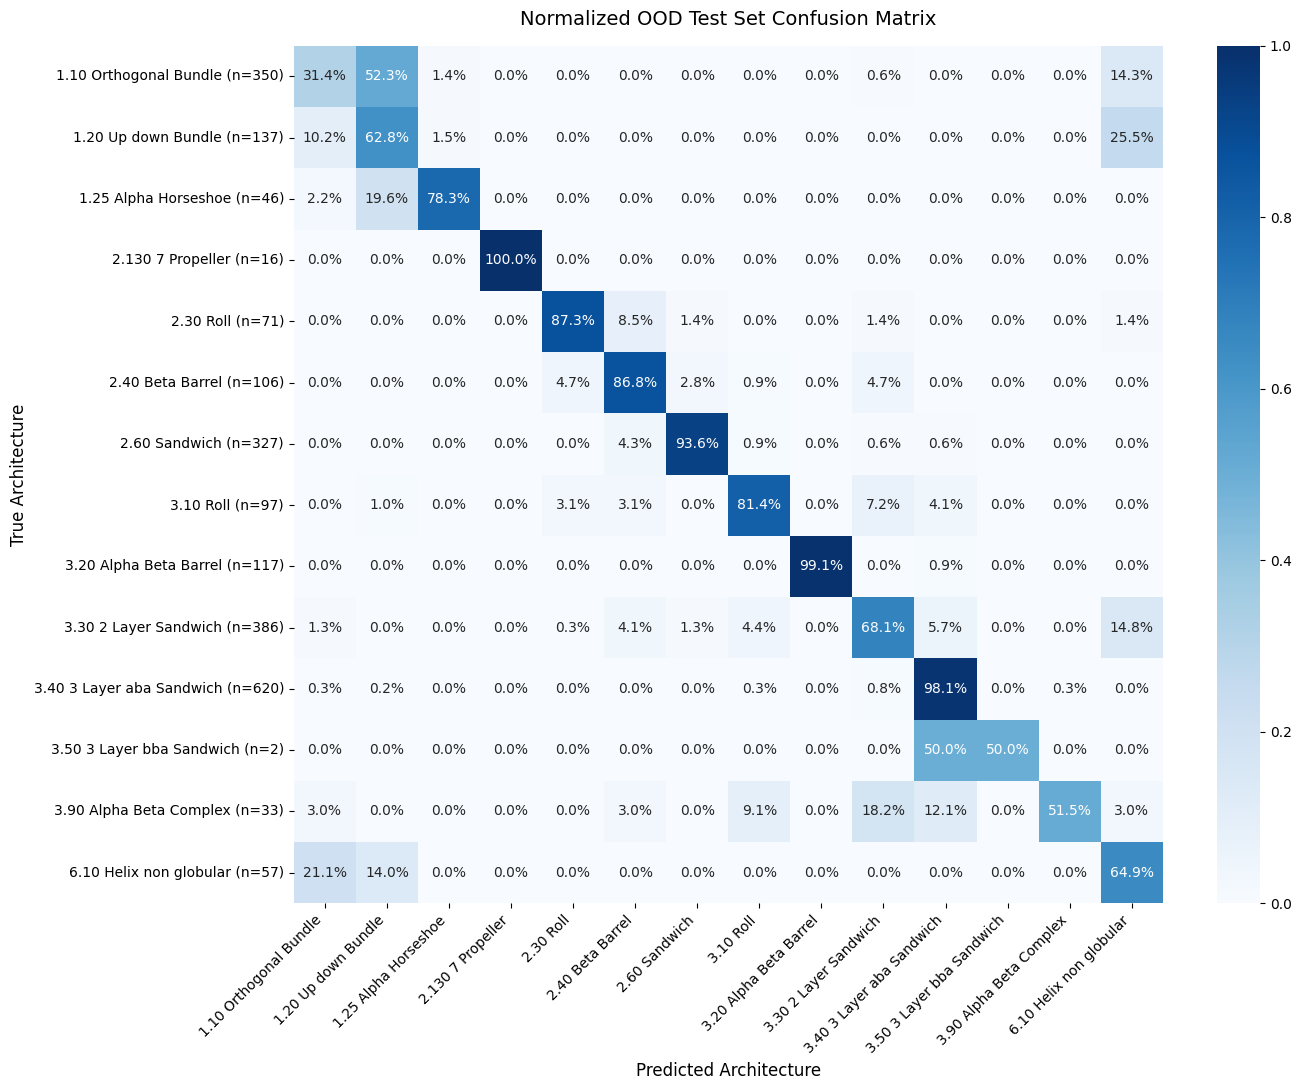

In [ ]:
vocab = list(dls_aug.vocab)
names = [v.replace("_", " ").replace("  ", " ").strip() for v in vocab] # "1.10__Orthogonal_Bundle" -> "1.10 Orthogonal Bundle"

idx = list(range(len(vocab)))
cm = confusion_matrix(true_labels, pred_labels, labels=idx, normalize='true')
counts = np.bincount(true_labels, minlength=len(vocab))
row_names = [f"{n} (n={c})" for n, c in zip(names, counts)]

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='.1%', cmap='Blues', cbar=True,
            xticklabels=names, yticklabels=row_names)
plt.title("Normalized OOD Test Set Confusion Matrix", fontsize=14, pad=15)
plt.xlabel("Predicted Architecture", fontsize=12)
plt.ylabel("True Architecture", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### **4.3. Predictions**

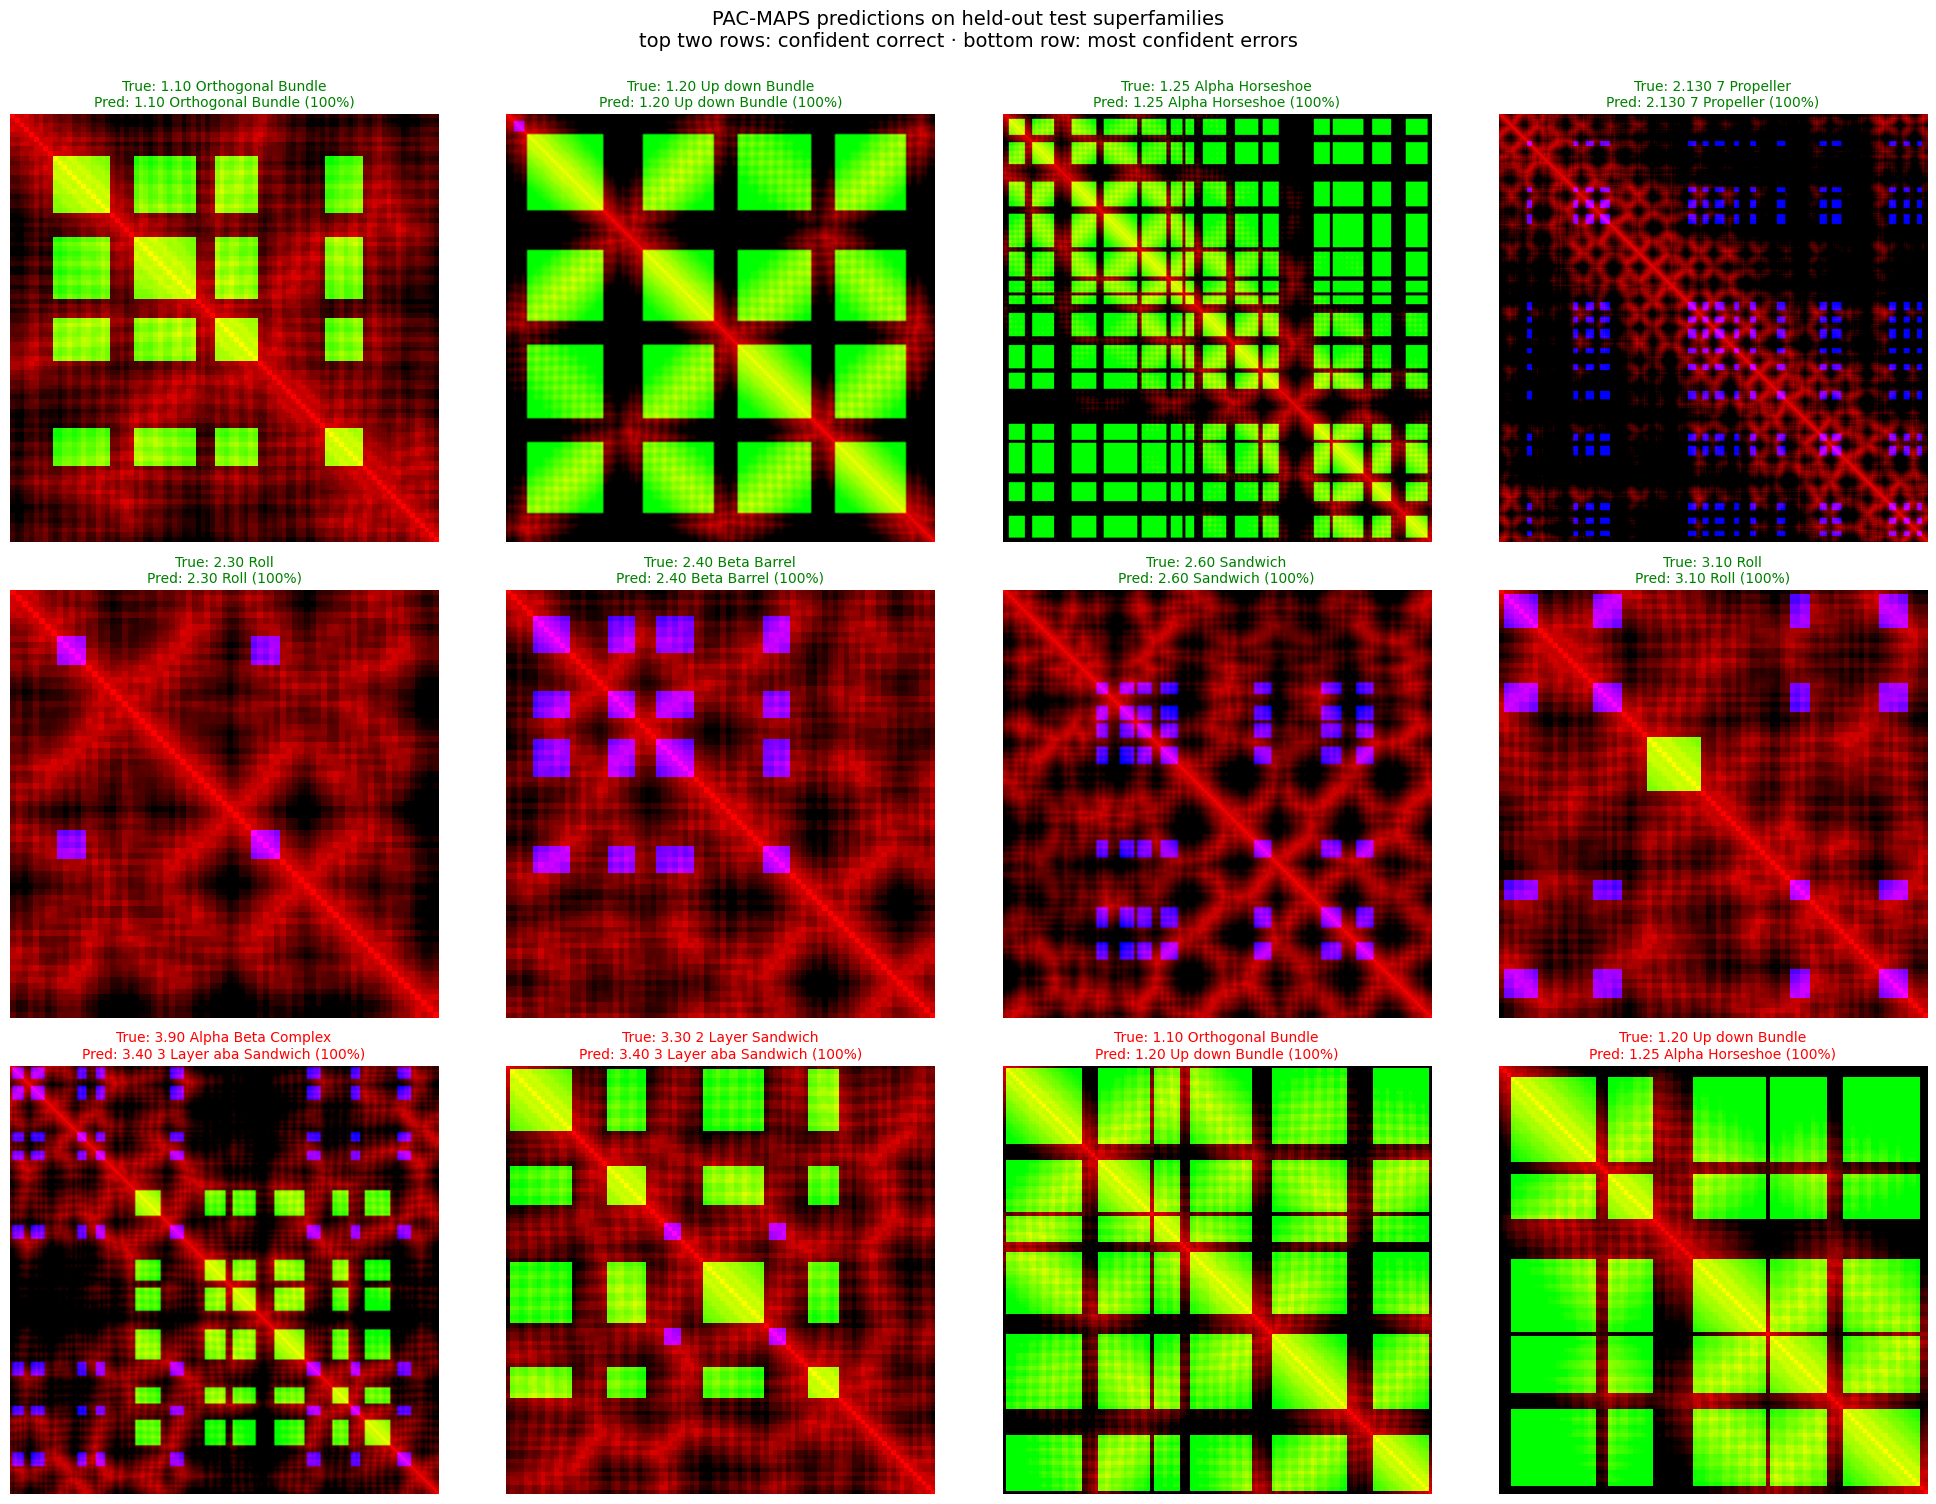

In [ ]:
probs, targs = learn.get_preds(dl=test_dl)
preds, conf = probs.argmax(1), probs.max(1).values
names = [v.replace("__", " ").replace("_", " ") for v in dls_aug.vocab]
correct = preds == targs

# most confident correct prediction per class (first 8 classes that have one)
right = []
for c in range(len(names)):
    idx = torch.where(correct & (targs == c))[0]
    if len(idx):
        right.append(idx[conf[idx].argmax()].item())
right = right[:8]

# most confident mistakes, one per (true, predicted) pair
wrong, seen = [], set()
for i in torch.where(~correct)[0][conf[~correct].argsort(descending=True)].tolist():
    pair = (targs[i].item(), preds[i].item())
    if pair not in seen:
        seen.add(pair); wrong.append(i)
    if len(wrong) == 4:
        break

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
for ax, i in zip(axes.flat, right + wrong):
    ok = correct[i].item()
    ax.imshow(Image.open(test_files[i]))
    ax.set_title(f"True: {names[targs[i]]}\nPred: {names[preds[i]]} ({conf[i]:.0%})",
                 fontsize=10, color="green" if ok else "red")
    ax.axis("off")

fig.suptitle("PAC-MAPS predictions on held-out test superfamilies\n"
             "top two rows: confident correct · bottom row: most confident errors",
             fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

## **5. Benchmarking PAC-MAPS against Foldseek**

Foldseek is the go-to structural search tool for bioinformaticians. If pointed at an unknown protein domain, we can find its closest known structural homologs to determine its architecture.

I'm going to use Foldseek on the test set of all 3 seed splits to find the nearest neighbour (i.e. the FoldsSeek top hit) for all test proteins — this will effectively function as the 'prediction'. I'll then score these with the same (balanced) accuracy as PAC-MAPs to compare performance and see how much structural architecture the model was able to learn from contact maps alone.



Download Foldseek

In [ ]:
! wget -q https://mmseqs.com/foldseek/foldseek-linux-avx2.tar.gz && tar xzf foldseek-linux-avx2.tar.gz

Creating directories for query and target PDBs based on test and train IDs.

In [ ]:
PDB_DIR = Path("/content/dompdb")
BENCH_ROOT = Path("/content/benchmark")

def make_benchmark_dirs(seed, test_ids, valid_ids):
    """Link the train and test structures for one split seed into benchmark_{train,test}_{seed}/."""
    stems = {p.stem for p in get_image_files(path)}        # the same domains the CNN saw
    sets = {
        "train": stems - set(test_ids) - set(valid_ids),   # train split only
        "test":  stems & set(test_ids),
    }
    for name, ids in sets.items():
        d = BENCH_ROOT / f"benchmark_{name}_{seed}"
        if d.exists():
            shutil.rmtree(d)
        d.mkdir(parents=True)
        missing = 0
        for i in ids:
            src = PDB_DIR / i
            if src.exists():
                (d / f"{i}.pdb").symlink_to(src)
            else:
                missing += 1
        print(f"seed {seed} | {name}: {len(ids) - missing} structures linked ({missing} missing)")
    return BENCH_ROOT / f"benchmark_test_{seed}", BENCH_ROOT / f"benchmark_train_{seed}"

Running Foldseek. Can take ~6-30 minutes.

In [ ]:
SEED = 2002
q_dir, t_dir = make_benchmark_dirs(SEED, test_ids, valid_ids)

!/content/foldseek/bin/foldseek easy-search {q_dir} {t_dir} hits_{SEED}.m8 tmp_{SEED} \
    --exhaustive-search 1 -e 10 \
    --format-output "query,target,evalue,bits,alntmscore,prob"

seed 2002 | train: 16195 structures linked (0 missing)
seed 2002 | test: 2365 structures linked (0 missing)
Create directory tmp_2002
easy-search /content/benchmark/benchmark_test_2002 /content/benchmark/benchmark_train_2002 hits_2002.m8 tmp_2002 --exhaustive-search 1 -e 10 --format-output query,target,evalue,bits,alntmscore,prob 

MMseqs Version:                    	463739e0014a1549a527de589102cde98f802f37
TMscore threshold                  	0
TMscore threshold mode             	0
LDDT threshold                     	0
Sort by structure bit score        	1
Alignment type                     	2
Exact TMscore                      	0
Substitution matrix                	aa:3di.out,nucl:3di.out
Add backtrace                      	false
Alignment mode                     	3
Alignment mode                     	0
E-value threshold                  	10
Seq. id. threshold                 	0
Min alignment length               	0
Seq. id. mode                      	0
Alternative alignments        

Get accuracy and balanced accuracy from Foldseek nearest neighbours search.

In [64]:
hits = pd.read_csv("hits_2002.m8", sep="\t", names=["query","target","evalue","bits","tm","prob"])
hits["query"]  = hits["query"].str.replace(".pdb", "", regex=False)
hits["target"] = hits["target"].str.replace(".pdb", "", regex=False)

arch = s40.set_index("id").architecture.astype(str)
hits["arch"] = hits.target.map(arch)

test = s40[s40.id.isin(test_ids)].set_index("id")
y_true = test.architecture.astype(str)

def score(y_pred, label):
    coverage = y_pred.notna().mean()
    y_pred = y_pred.fillna("no_hit")      # no-hit queries count as wrong
    print(f"\033[1m{label:<6}\033[0m \033[1mCoverage:\033[0m {coverage:.3f}  \033[1mAccuracy\033[0m: {accuracy_score(y_true, y_pred):.3f}  "
          f"\033[1mBal. Accuracy:\033[0m {balanced_accuracy_score(y_true, y_pred):.3f}")

# top-1: best hit per query
top1 = hits.sort_values("bits", ascending=False).drop_duplicates("query")
score(top1.set_index("query").arch.reindex(y_true.index), "top-1")

# top-5: majority vote among each query's 5 best hits, ties broken by summed bit score
top5 = hits.sort_values(["query", "bits"], ascending=[True, False]).groupby("query").head(5)
votes = (top5.groupby(["query", "arch"])
             .agg(n=("bits", "size"), bits=("bits", "sum"))
             .reset_index()
             .sort_values(["query", "n", "bits"], ascending=[True, False, False])
             .drop_duplicates("query"))
score(votes.set_index("query").arch.reindex(y_true.index), "top-5")

top-1  Coverage: 0.982  Accuracy: 0.825  Bal. Accuracy: 0.795
top-5  Coverage: 0.982  Accuracy: 0.837  Bal. Accuracy: 0.807
